In [1]:
!pip install -q pyspark
from google.colab import drive
drive.mount('/content/drive')

from pyspark.sql import SparkSession
spark = (SparkSession.builder
         .appName("YelpSentiment")
         .config("spark.driver.memory", "10g")
         .getOrCreate())

df       = spark.read.parquet("/content/drive/MyDrive/yelp_project/reviews_clean.parquet")
business = spark.read.parquet("/content/drive/MyDrive/yelp_project/business.parquet")

# while developing: work on a 5% sample, then run the final version on all data
sample = df.sample(fraction=0.05, seed=42)

Mounted at /content/drive


In [2]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

from pyspark.sql.functions import (
    col, length, size, split, avg, expr
)

# Create a folder for saving charts
os.makedirs("figures", exist_ok=True)

# Set chart style
sns.set_theme(style="whitegrid")



# Exploratory Data Analysis (EDA)

This section explores the Yelp reviews dataset to understand its distribution, review lengths, and changes in review activity over time.

The analysis includes star and sentiment distribution, review length comparison, and yearly review trends.



### Task 1 — Star and Label Distribution

This task examines the number of reviews for each star rating and compares the total number of positive and negative reviews.

Positive reviews have 4–5 stars, while negative reviews have 1–2 stars. Three-star reviews were removed during Phase 1.


In [3]:

# Count reviews for each star rating
stars_pd = (df.groupBy("stars")
              .count()
              .orderBy("stars")
              .toPandas())

# Count positive and negative reviews
label_pd = (df.groupBy("label")
              .count()
              .orderBy("label")
              .toPandas())

# Replace numerical labels with names
label_pd["label"] = label_pd["label"].map({
    0: "Negative",
    1: "Positive"
})

print("Reviews per star rating:")
print(stars_pd)

print("\nPositive vs Negative reviews:")
print(label_pd)


Reviews per star rating:
   stars    count
0    1.0  1069507
1    2.0   544228
2    4.0  1452876
3    5.0  3231568

Positive vs Negative reviews:
      label    count
0  Negative  1613735
1  Positive  4684444


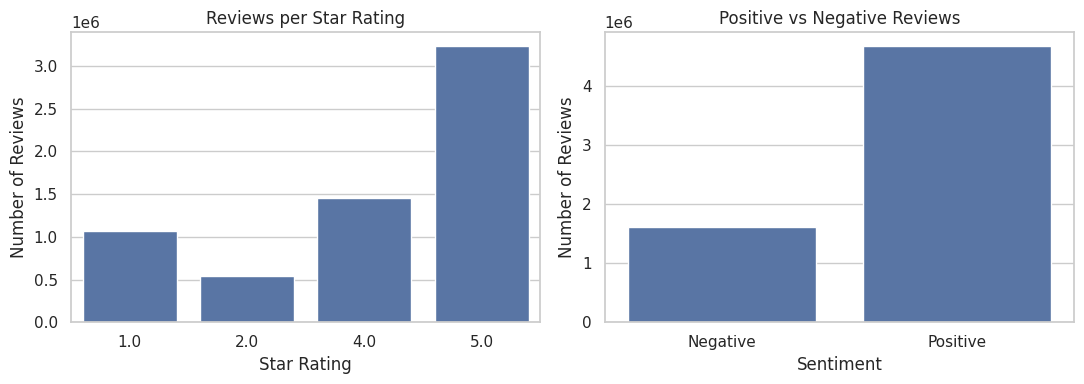

In [4]:

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Reviews per star rating
sns.barplot(
    data=stars_pd,
    x="stars",
    y="count",
    ax=ax[0]
)

ax[0].set_title("Reviews per Star Rating")
ax[0].set_xlabel("Star Rating")
ax[0].set_ylabel("Number of Reviews")

# Positive vs Negative reviews
sns.barplot(
    data=label_pd,
    x="label",
    y="count",
    ax=ax[1]
)

ax[1].set_title("Positive vs Negative Reviews")
ax[1].set_xlabel("Sentiment")
ax[1].set_ylabel("Number of Reviews")

plt.tight_layout()

plt.savefig("figures/01_label_distribution.png", dpi=300)

plt.show()



**Interpretation:**

The dataset contains significantly more positive reviews than negative reviews. Positive reviews represent approximately 74.4% of the dataset, while negative reviews represent 25.6%.

This shows that the dataset is imbalanced, with almost three positive reviews for every negative review. Therefore, accuracy alone may not be enough to evaluate the models in Phase 3. Metrics such as Precision, Recall, and F1-score will also be important.



### Task 2 — Review Length

This task compares the length of positive and negative reviews by calculating the average, median, and 95th percentile of the number of words.

A histogram will also be created to visualize the differences in review length between the two sentiment classes.


In [5]:

# Calculate the number of characters and words in each review
df_len = (df.withColumn("n_chars", length("text"))
            .withColumn("n_words", size(split(col("text"), r"\s+"))))

# Calculate average, median, and 95th percentile
length_stats = (df_len.groupBy("label")
    .agg(
        avg("n_words").alias("avg_words"),
        expr("percentile_approx(n_words, 0.5)").alias("median_words"),
        expr("percentile_approx(n_words, 0.95)").alias("p95_words")
    )
    .orderBy("label")
)

print("Review length statistics:")
length_stats.show()


Review length statistics:
+-----+-----------------+------------+---------+
|label|        avg_words|median_words|p95_words|
+-----+-----------------+------------+---------+
|    0| 134.102872528637|          98|      368|
|    1|91.80663041334255|          66|      251|
+-----+-----------------+------------+---------+



In [6]:

# Select review length and sentiment
# Use 1% of the dataset for plotting
len_pd = (df_len.select("n_words", "label")
                .sample(fraction=0.01, seed=42)
                .toPandas())

# Remove the longest 1% of reviews for a clearer chart
len_pd = len_pd[
    len_pd["n_words"] <= len_pd["n_words"].quantile(0.99)
]

# Convert numerical labels into readable names
len_pd["label"] = len_pd["label"].map({
    0: "Negative",
    1: "Positive"
})

print("Visualization sample size:", len(len_pd))
print(len_pd.head())


Visualization sample size: 62422
   n_words     label
0       88  Positive
1       41  Positive
2       79  Positive
3       84  Negative
4       51  Positive


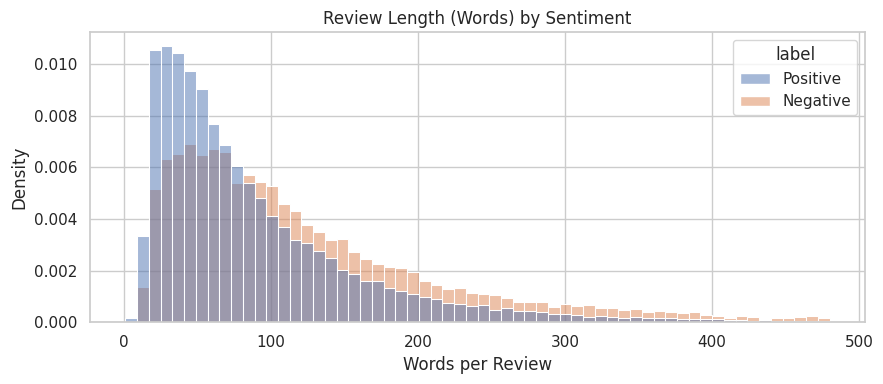

In [7]:

plt.figure(figsize=(9, 4))

sns.histplot(
    data=len_pd,
    x="n_words",
    hue="label",
    bins=60,
    stat="density",
    common_norm=False
)

plt.title("Review Length (Words) by Sentiment")
plt.xlabel("Words per Review")
plt.ylabel("Density")

plt.tight_layout()

plt.savefig("figures/02_review_length.png", dpi=300)

plt.show()



**Interpretation:**

Negative reviews are noticeably longer than positive reviews across all summary metrics:
- **Negative (0):** Average of **134.1 words** (median **98 words**, 95th percentile **368 words**).
- **Positive (1):** Average of **91.8 words** (median **66 words**, 95th percentile **251 words**).

This confirms that dissatisfied customers tend to write longer, more detailed descriptions when complaining, whereas satisfied customers often leave shorter, more concise positive feedback.



### Task 3 — Reviews and Sentiment Over Time

This task examines the number of Yelp reviews submitted each year and calculates the percentage of positive reviews over time.

The analysis will help identify changes in review activity and sentiment trends, including the drop in reviews during 2020.


In [8]:

# Group reviews by year
year_pd = (df.groupBy("year")
    .agg(
        expr("count(*)").alias("reviews"),
        avg("label").alias("positive_share")
    )
    .orderBy("year")
    .toPandas()
)

# Convert positive share into percentage
year_pd["positive_percentage"] = year_pd["positive_share"] * 100

print("Yearly review statistics:")
print(year_pd)


Yearly review statistics:
    year  reviews  positive_share  positive_percentage
0   2005      683        0.877013            87.701318
1   2006     3201        0.890347            89.034677
2   2007    12458        0.851100            85.109969
3   2008    39220        0.838424            83.842427
4   2009    61614        0.795160            79.516019
5   2010   115549        0.793758            79.375849
6   2011   194809        0.780200            78.020009
7   2012   245187        0.762051            76.205101
8   2013   332536        0.755190            75.519042
9   2014   461656        0.753516            75.351560
10  2015   616159        0.748635            74.863469
11  2016   686637        0.746623            74.662303
12  2017   744886        0.746120            74.611954
13  2018   829238        0.741390            74.139029
14  2019   832821        0.733476            73.347574
15  2020   517544        0.728717            72.871679
16  2021   574499        0.705932      

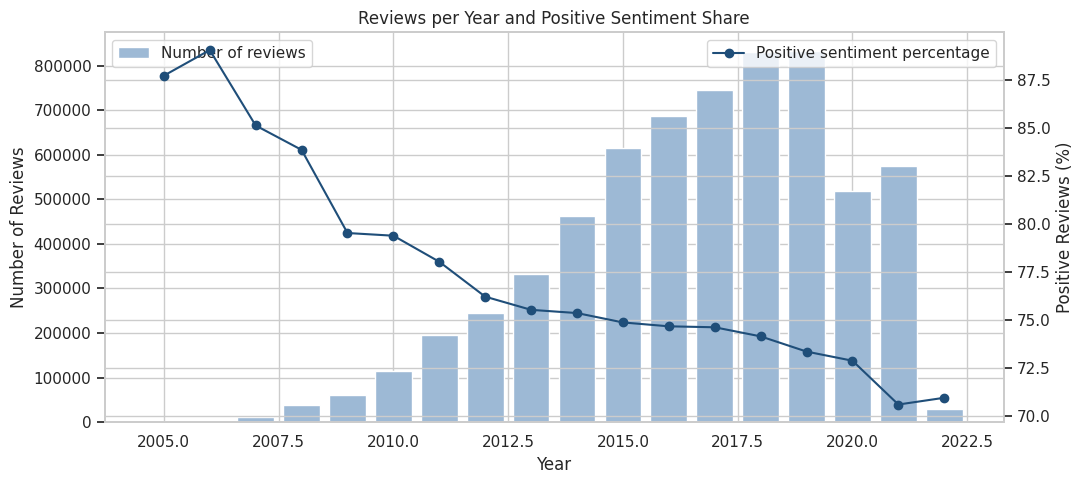

In [9]:

fig, ax1 = plt.subplots(figsize=(11, 5))

# Bar chart for the number of reviews
ax1.bar(
    year_pd["year"],
    year_pd["reviews"],
    color="#9DB9D5",
    label="Number of reviews"
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Number of Reviews")
ax1.set_title("Reviews per Year and Positive Sentiment Share")

# Line chart for positive sentiment percentage
ax2 = ax1.twinx()

ax2.plot(
    year_pd["year"],
    year_pd["positive_percentage"],
    color="#1F4E79",
    marker="o",
    label="Positive sentiment percentage"
)

ax2.set_ylabel("Positive Reviews (%)")

# Add legends
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.tight_layout()

plt.savefig("figures/03_reviews_per_year.png", dpi=300)

plt.show()



**Interpretation:**

The chart shows how Yelp review activity changes over time, together with the percentage of positive reviews each year.

The number of reviews increases over the years until 2019, followed by a noticeable drop in 2020, which may be related to the COVID-19 pandemic. Review activity recovers in 2021.

The 2022 data is incomplete, so it should not be directly compared with full years. The positive sentiment percentage also helps show whether customer opinions changed over time.
